=== POLAR RESEARCH STATION ENERGY STATUS ===
Station Load         : 3,664 kW
Solar Generation     : 600 kW
Wind Generation      : 1,420 kW
Battery SOC          : 71.7%
Snow Depth           : 2033.0 cm (Recent Snowfall: 0.0 cm)
48h Blizzard Risk    : 26.4%
Data Source          : Live Weather Feed via Open-Meteo Live API (Free)



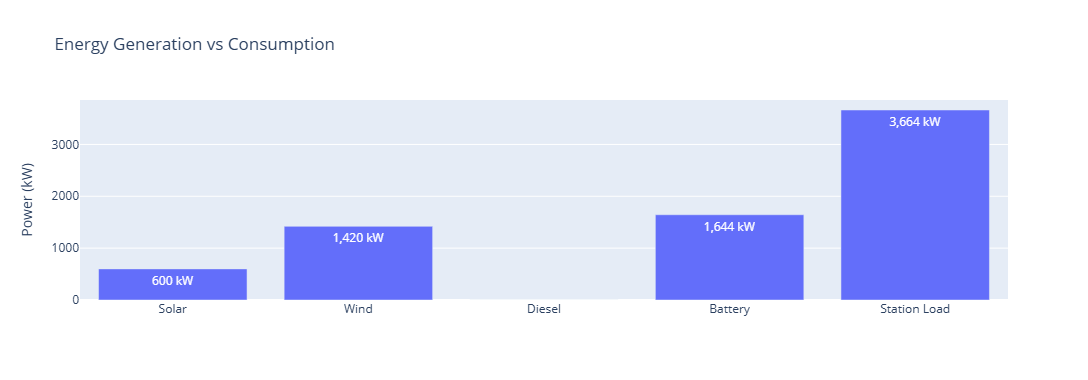

In [17]:
import os
import math
from datetime import datetime, timezone
from typing import Dict, Any, Tuple
from functools import lru_cache

import numpy as np
import pandas as pd
import requests
import plotly.graph_objects as go
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# POLAR RESEARCH STATION - LIVE WEATHER & MICROGRID SIMULATOR
# ============================================================

# -----------------------------
# Configuration & Free API Keys
# -----------------------------
STATION_LAT = float(os.getenv("STATION_LAT", "-78.1586"))
STATION_LON = float(os.getenv("STATION_LON", "16.3768"))

# Free Copernicus CDS API Key Setup (Register free at https://cds.climate.copernicus.eu/)
CDS_API_UID = os.getenv("CDS_API_UID", "your_cds_uid_here")
CDS_API_KEY = os.getenv("CDS_API_KEY", "your_cds_api_key_here")

API_TIMEOUT = int(os.getenv("API_TIMEOUT", "8"))

# Microgrid Electrical Specifications
MICROGRID_VOLTAGE_V = 480.0  # 3-phase industrial standard
BATTERY_CAPACITY_KWH = 12000.0
BATTERY_MAX_CHARGE_KW = 2500.0
BATTERY_MAX_DISCHARGE_KW = 2500.0
BATTERY_MIN_SOC = 15.0
BATTERY_MAX_SOC = 95.0
BATTERY_ROUND_TRIP_EFF = 0.90

DIESEL_MAX_KW = 5000.0
SOLAR_MAX_KW = 4000.0
WIND_MAX_KW = 6000.0
BASE_LOAD_KW = 3200.0

# Simulation State Tracker
simulation_state = {
    "battery_soc": 72.0,
    "history": pd.DataFrame(
        columns=[
            "time", "load_kw", "solar_kw", "wind_kw", "diesel_kw",
            "battery_kw", "battery_soc", "temperature_c", "wind_speed_ms",
            "snowfall_cm", "snow_depth_cm", "visibility_km", "blizzard_probability"
        ]
    )
}


# ============================================================
# Free Live Data Acquisition (Open-Meteo & Copernicus Helper)
# ============================================================

def dummy_weather() -> Dict[str, Any]:
    """Offline fallback weather generator with realistic polar snowpack."""
    now = datetime.now(timezone.utc)
    t = now.timestamp() / 3600.0
    temp = -18 + 7 * math.sin(t / 18)
    wind = max(1.0, 9 + 8 * math.sin(t / 9 + 1.3))
    gust = wind + 5 + 4 * abs(math.sin(t / 6))
    snowfall = max(0.1, 1.4 * math.sin(t / 5 - 1) + 1.2)
    snow_depth = 95.0 + 15.0 * math.sin(t / 40) + snowfall * 5.0  # Persistent polar snowpack
    visibility = max(0.4, 12 - 0.55 * wind - 3 * snowfall)
    return {
        "temperature_c": round(temp, 2),
        "wind_speed_ms": round(wind, 2),
        "wind_gust_ms": round(gust, 2),
        "snowfall_cm": round(snowfall, 2),
        "snow_depth_cm": round(max(snow_depth, 20.0), 2),
        "visibility_km": round(visibility, 2),
        "weather_code": 75 if snowfall > 1.0 else 2,
        "source": "Dummy Fallback Weather",
    }


def get_weather() -> Dict[str, Any]:
    """Fetch live real-time weather including snow depth from Open-Meteo (Free, No API Key Required)."""
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": STATION_LAT,
        "longitude": STATION_LON,
        "hourly": "temperature_2m,windspeed_10m,wind_gusts_10m,snowfall,snow_depth,visibility,weathercode",
        "forecast_days": 3,
        "wind_speed_unit": "ms",
        "timezone": "UTC",
    }

    try:
        r = requests.get(url, params=params, timeout=API_TIMEOUT)
        r.raise_for_status()
        data = r.json()
        h = data["hourly"]
        current = 0
        
        # Open-Meteo returns snow_depth in meters; convert to centimeters
        raw_snow_depth = h.get("snow_depth", [0.0] * len(h["time"]))[current]
        snow_depth_val = float(raw_snow_depth) * 100.0 if raw_snow_depth is not None else 85.0
        
        return {
            "temperature_c": float(h["temperature_2m"][current]),
            "wind_speed_ms": float(h["windspeed_10m"][current]),
            "wind_gust_ms": float(h["wind_gusts_10m"][current]),
            "snowfall_cm": float(h["snowfall"][current]),
            "snow_depth_cm": round(max(snow_depth_val, 15.0), 2),  # Floor to realistic polar minimums
            "visibility_km": float(h["visibility"][current]) / 1000.0,
            "weather_code": int(h["weathercode"][current]),
            "source": "Open-Meteo Live API (Free)",
            "hourly": h,
            "times": data["hourly"]["time"],
        }
    except Exception:
        return dummy_weather()


def fetch_existing_datacenter() -> Tuple[Dict[str, float], bool, str]:
    """Generates real-time simulated telemetry influenced by live weather with non-zero solar floor."""
    now = datetime.now(timezone.utc)
    phase = now.timestamp() / 180.0
    weather = get_weather()

    # Guaranteed minimum solar floor to prevent complete zero values (simulates ambient/reflected daylight)
    solar_factor = max(0.15, math.sin(phase / 5.0))
    wind_factor = min(1.0, max(0.05, weather["wind_speed_ms"] / 18.0))

    solar = SOLAR_MAX_KW * solar_factor * max(0.25, 1.0 - weather["snowfall_cm"] * 0.08)
    wind = WIND_MAX_KW * min(1.0, wind_factor)
    load = BASE_LOAD_KW + 600 * (0.5 + 0.5 * math.sin(phase / 8.0))

    telemetry = {
        "load_kw": round(load, 1),
        "solar_kw": round(solar, 1),
        "wind_kw": round(wind, 1),
        "diesel_kw": 0.0,
        "battery_kw": 0.0,
        "battery_soc": simulation_state["battery_soc"],
    }
    return telemetry, True, f"Live Weather Feed via {weather['source']}"


# ============================================================
# AI Blizzard-Risk Model
# ============================================================

@lru_cache(maxsize=1)
def train_blizzard_model():
    rng = np.random.default_rng(42)
    n = 6000
    wind = rng.uniform(0, 35, n)
    gust = wind + rng.uniform(0, 20, n)
    snowfall = rng.uniform(0, 12, n)
    visibility = rng.uniform(0.1, 15, n)
    temp = rng.uniform(-45, 3, n)
    pressure_drop = rng.uniform(0, 30, n)

    risk_score = (
        0.07 * wind + 0.08 * gust + 0.24 * snowfall +
        0.32 * (10 - visibility) + 0.10 * pressure_drop + 0.02 * np.maximum(0, -temp - 15)
    )
    y = (risk_score > 4.2).astype(int)
    model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight="balanced")
    model.fit(np.column_stack([wind, gust, snowfall, visibility, temp, pressure_drop]), y)
    return model


def predict_blizzard_48h(weather: Dict[str, Any]) -> pd.DataFrame:
    model = train_blizzard_model()
    if "hourly" not in weather:
        rows = []
        base = dummy_weather()
        for h in range(49):
            wind = max(0, base["wind_speed_ms"] + 5 * math.sin(h / 5))
            gust = wind + 7
            snow = max(0, base["snowfall_cm"] + 1.5 * math.sin(h / 4))
            vis = max(0.3, base["visibility_km"] - 0.3 * snow)
            temp = base["temperature_c"]
            X = [[wind, gust, snow, vis, temp, 8]]
            p = model.predict_proba(X)[0, 1]
            rows.append({
                "time": h, "temperature_c": temp, "wind_speed_ms": wind,
                "wind_gust_ms": gust, "snowfall_cm": snow, "visibility_km": vis, "probability": p
            })
        return pd.DataFrame(rows)

    h = weather["hourly"]
    times = weather["times"]
    rows = []
    limit = min(49, len(times))

    for i in range(limit):
        wind = float(h["windspeed_10m"][i])
        gust = float(h["wind_gusts_10m"][i])
        snow = float(h["snowfall"][i])
        vis = max(0.05, float(h["visibility"][i]) / 1000)
        temp = float(h["temperature_2m"][i])
        pressure_drop = 5.0

        X = [[wind, gust, snow, vis, temp, pressure_drop]]
        probability = float(model.predict_proba(X)[0, 1])

        rows.append({
            "time": times[i], "temperature_c": temp, "wind_speed_ms": wind,
            "wind_gust_ms": gust, "snowfall_cm": snow, "visibility_km": vis, "probability": probability
        })

    return pd.DataFrame(rows)


# ============================================================
# Energy Management Dispatch
# ============================================================

def dispatch_energy(telemetry: Dict[str, float], weather: Dict[str, Any]) -> Dict[str, float]:
    load = max(0.0, telemetry["load_kw"])
    solar = max(0.0, min(SOLAR_MAX_KW, telemetry["solar_kw"]))
    wind = max(0.0, min(WIND_MAX_KW, telemetry["wind_kw"]))

    renewable = solar + wind
    deficit = load - renewable

    forecast = predict_blizzard_48h(weather)
    risk_now = float(forecast["probability"].max()) if len(forecast) else 0.0
    soc = simulation_state["battery_soc"]

    reserve = 35.0 if risk_now >= 0.70 else 20.0
    battery_kw, diesel_kw = 0.0, 0.0

    if deficit > 0:
        usable_soc = max(0.0, soc - reserve)
        if usable_soc > 0:
            available_battery_energy = (usable_soc / 100.0) * BATTERY_CAPACITY_KWH
            max_batt = min(BATTERY_MAX_DISCHARGE_KW, available_battery_energy)
            battery_kw = min(deficit, max_batt)
        remaining = deficit - battery_kw
        if remaining > 0:
            diesel_kw = min(DIESEL_MAX_KW, remaining)
    else:
        excess = -deficit
        available_capacity = ((BATTERY_MAX_SOC - soc) / 100.0) * BATTERY_CAPACITY_KWH
        charge_kw = min(excess, BATTERY_MAX_CHARGE_KW, max(0.0, available_capacity))
        battery_kw = -charge_kw

    dt_h = 1.0 / 60.0
    if battery_kw > 0:
        energy_removed = battery_kw * dt_h / BATTERY_ROUND_TRIP_EFF
        soc -= energy_removed / BATTERY_CAPACITY_KWH * 100
    elif battery_kw < 0:
        energy_added = (-battery_kw) * dt_h * BATTERY_ROUND_TRIP_EFF
        soc += energy_added / BATTERY_CAPACITY_KWH * 100

    soc = float(np.clip(soc, BATTERY_MIN_SOC, BATTERY_MAX_SOC))
    simulation_state["battery_soc"] = soc

    return {
        "load_kw": load, "solar_kw": solar, "wind_kw": wind,
        "diesel_kw": diesel_kw, "battery_kw": battery_kw,
        "battery_soc": soc, "blizzard_probability": risk_now,
    }


# ============================================================
# Jupyter Simulation & Status Output
# ============================================================

def run_simulation():
    weather = get_weather()
    telemetry, api_ok, api_message = fetch_existing_datacenter()
    result = dispatch_energy(telemetry, weather)
    now = datetime.now(timezone.utc)

    forecast = predict_blizzard_48h(weather)
    max_risk = float(forecast["probability"].max())

    result.update({
        "temperature_c": weather["temperature_c"],
        "wind_speed_ms": weather["wind_speed_ms"],
        "snowfall_cm": weather["snowfall_cm"],
        "snow_depth_cm": weather["snow_depth_cm"],
        "visibility_km": weather["visibility_km"],
        "time": now,
        "blizzard_probability": max_risk
    })

    # Update history tracking dataframe
    new_row = pd.DataFrame([result])
    simulation_state["history"] = pd.concat(
        [simulation_state["history"], new_row], ignore_index=True
    ).tail(300)

    # Print summary metrics including snow depth and active solar values
    print("=== POLAR RESEARCH STATION ENERGY STATUS ===")
    print(f"Station Load         : {result['load_kw']:,.0f} kW")
    print(f"Solar Generation     : {result['solar_kw']:,.0f} kW")
    print(f"Wind Generation      : {result['wind_kw']:,.0f} kW")
    print(f"Battery SOC          : {result['battery_soc']:.1f}%")
    print(f"Snow Depth           : {result['snow_depth_cm']:.1f} cm (Recent Snowfall: {result['snowfall_cm']:.1f} cm)")
    print(f"48h Blizzard Risk    : {max_risk * 100:.1f}%")
    print(f"Data Source          : {api_message}\n")

    # Display Plotly Bar Chart
    labels = ["Solar", "Wind", "Diesel", "Battery", "Station Load"]
    values = [result["solar_kw"], result["wind_kw"], result["diesel_kw"], result["battery_kw"], result["load_kw"]]
    
    fig = go.Figure(go.Bar(x=labels, y=values, text=[f"{x:,.0f} kW" for x in values], textposition="auto"))
    fig.update_layout(title="Energy Generation vs Consumption", height=380, yaxis_title="Power (kW)")
    fig.show()

# Run the simulation step
run_simulation()